# Do the respondent vectors help?
Compare the frozen selected model with correct, averaged, zeroed and shuffled development vectors. No fitting or final-test access. These validation questions have already been used for model selection.

In [1]:
import os, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT = ROOT / "outputs"
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache/matplotlib")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
get_ipython().run_line_magic("matplotlib", "inline")
def read_json(name): return json.loads((ROOT / name).read_text())
def sha(name): return hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
paths = ["outputs/selected_response_model.npz", "outputs/development_validation_predictions.npz",
         "outputs/question_answer_features_prior_65.npy", "outputs/question_answer_index.json",
         "outputs/response_scale_priors.json", "data/processed/question_bank.json", "outputs/model_comparison.json",
         "data/heldout/validation_policy_wave4.parquet", "data/heldout/validation_maximization_wave1_3.parquet"]
hashes = {p: sha(p) for p in paths}
report = read_json("outputs/model_comparison.json")
for p, digest in hashes.items():
    expected = report.get("files", {}).get(p, {}).get("sha256", report.get("input_sha256", {}).get(p))
    if expected is not None: assert digest == expected, p
with np.load(OUT / "selected_response_model.npz", allow_pickle=False) as f:
    beta, W, z, model_pids = [f[k].copy() for k in ["state__beta", "state__W", "development_vectors", "development_person_ids"]]
with np.load(OUT / "development_validation_predictions.npz", allow_pickle=False) as f:
    saved, pids, qids, counts = [f[k].copy() for k in ["probabilities", "person_ids", "item_ids", "option_counts"]]
assert np.array_equal(pids, model_pids)
frames = [pd.read_parquet(ROOT / p).set_index("pid") for p in paths[-2:]]
y = pd.concat(frames, axis=1).loc[pids.tolist(), qids.tolist()].to_numpy(dtype=int) - 1
assert y.shape == (300, 8) and np.all((y >= 0) & (y < counts[None, :]))
features = np.load(OUT / "question_answer_features_prior_65.npy")
index = pd.DataFrame(read_json("outputs/question_answer_index.json"))
items = {q["item_id"]: q for q in read_json("data/processed/question_bank.json")["items"]}
priors = {tuple(p["option_labels"]): np.array(p["probabilities"]) for p in read_json("outputs/response_scale_priors.json")}
def predict(vectors):
    p = np.zeros(saved.shape, dtype=np.float64)
    for j, q in enumerate(qids):
        rows = index[index.item_id == q].sort_values("answer_index")
        assert np.array_equal(rows.answer_index, np.arange(counts[j]))
        e = features[rows.embedding_row.to_numpy()].astype(np.float64)
        logits = (vectors @ W + beta) @ e[:, :64].T + e[:, -1]
        exp = np.exp(logits - logits.max(axis=1, keepdims=True))
        p[:, j, :counts[j]] = exp / exp.sum(axis=1, keepdims=True)
    return p
own = predict(z)
assert np.allclose(own, saved, atol=2e-6, rtol=2e-5)
population = np.zeros_like(own)
for j, q in enumerate(qids):
    labels = tuple(o["label"] for o in items[q]["options"])
    population[:, j, :counts[j]] = priors.get(labels, np.ones(counts[j]) / counts[j])
predictions = {"Own vector": own,
               "Mean vector": predict(np.broadcast_to(z.mean(0), z.shape)),
               "Zero vector": predict(np.zeros_like(z)),
               "Population baseline": population}
people, questions = np.arange(len(pids))[:, None], np.arange(len(qids))[None, :]
human_shares = np.stack([(y == k).mean(0) for k in range(saved.shape[-1])], axis=-1)
def losses(p): return -np.log(np.clip(p[people, questions, y], 1e-12, 1))
def correct(p): return p.argmax(-1) == y
def metrics(p):
    loss, hit = losses(p), correct(p)
    tv = np.abs(p.mean(0) - human_shares).sum(-1) / 2
    return {"accuracy": float(hit.mean()), "nll": float(loss.mean()), "distribution_TV": float(tv.mean()),
            "policy_accuracy": float(hit[:, :2].mean()), "policy_nll": float(loss[:, :2].mean()),
            "per_question": [{"item_id": str(q), "accuracy": float(hit[:, j].mean()), "nll": float(loss[:, j].mean())} for j, q in enumerate(qids)]}
results = {name: metrics(p) for name, p in predictions.items()}
assert np.isclose(results["Population baseline"]["nll"], report["population_baseline"]["nll"], atol=1e-6)
display(pd.DataFrame(results).T.drop(columns="per_question").astype(float).round(4))

,accuracy,nll,distribution_TV,policy_accuracy,policy_nll
Own vector,0.3596,1.5155,0.1275,0.4883,1.3149
Mean vector,0.3662,1.5055,0.1211,0.5283,1.3248
Zero vector,0.3662,1.5037,0.1204,0.5283,1.3096
Population baseline,0.3662,1.5127,0.1298,0.5283,1.3414


## Shuffle check and uncertainty
Shuffle whole vectors between people, preserving their predictions across all eight questions. Bootstrap whole respondents for paired comparisons. Intervals describe these 300 people on these eight questions; they do not account for model selection or new questions.

In [2]:
rng = np.random.default_rng(20261023)
shuffle_results = []
for _ in range(1000):
    shuffled = own[rng.permutation(len(pids))]
    shuffle_results.append([correct(shuffled).mean(), losses(shuffled).mean(),
                            correct(shuffled)[:, :2].mean(), losses(shuffled)[:, :2].mean()])
shuffle_results = np.asarray(shuffle_results)
shuffle_summary = {metric: {"mean": float(shuffle_results[:, j].mean()),
                            "range_95": np.quantile(shuffle_results[:, j], [.025, .975]).tolist()}
                   for j, metric in enumerate(["accuracy", "nll", "policy_accuracy", "policy_nll"])}
# A permutation preserves aggregate survey shares exactly (up to rounding).
assert np.allclose(own.mean(0), own[rng.permutation(len(pids))].mean(0), atol=1e-12)
bootstrap = {}
for name in ["Mean vector", "Zero vector", "Population baseline"]:
    differences = np.column_stack([(correct(own).astype(float) - correct(predictions[name])).mean(1),
                                   (losses(own) - losses(predictions[name])).mean(1)])
    resamples = differences[rng.integers(0, len(pids), size=(3000, len(pids)))].mean(1)
    bootstrap[name] = {metric: {"own_minus_comparator": float(differences[:, j].mean()),
                               "paired_respondent_bootstrap_95": np.quantile(resamples[:, j], [.025, .975]).tolist()}
                       for j, metric in enumerate(["accuracy", "nll"])}
print("Shuffled vectors:", json.dumps(shuffle_summary, indent=2))
print("Own vector minus comparator:", json.dumps(bootstrap, indent=2))
per_question = pd.DataFrame({name: [r["nll"] for r in value["per_question"]] for name, value in results.items()}, index=qids)
display(per_question.round(4))

Shuffled vectors: {
  "accuracy": {
    "mean": 0.27022333333333337,
    "range_95": [
      0.25083333333333335,
      0.2891875
    ]
  },
  "nll": {
    "mean": 1.7769517400656383,
    "range_95": [
      1.7324817024396038,
      1.8212314529413893
    ]
  },
  "policy_accuracy": {
    "mean": 0.3722883333333333,
    "range_95": [
      0.33666666666666667,
      0.41
    ]
  },
  "policy_nll": {
    "mean": 1.6115532185733796,
    "range_95": [
      1.5443148592122358,
      1.6846998516784786
    ]
  }
}
Own vector minus comparator: {
  "Mean vector": {
    "accuracy": {
      "own_minus_comparator": -0.006666666666666667,
      "paired_respondent_bootstrap_95": [
        -0.03,
        0.017083333333333332
      ]
    },
    "nll": {
      "own_minus_comparator": 0.010023751099833368,
      "paired_respondent_bootstrap_95": [
        -0.024957866261213102,
        0.044922659173060965
      ]
    }
  },
  "Zero vector": {
    "accuracy": {
      "own_minus_comparator": -0.00666

,Own vector,Mean vector,Zero vector,Population baseline
QID287_7,1.2330,1.2571,1.2423,1.3047
QID287_10,1.3968,1.3924,1.3769,1.3781
QID239_1,1.5407,1.6104,1.6071,1.5680
QID239_2,1.5719,1.5392,1.5465,1.5547
QID239_3,1.7333,1.6080,1.6155,1.5924
QID239_4,1.6956,1.5626,1.5569,1.5595
QID239_5,1.4597,1.4860,1.4823,1.5444
QID239_6,1.4929,1.5878,1.6022,1.5997


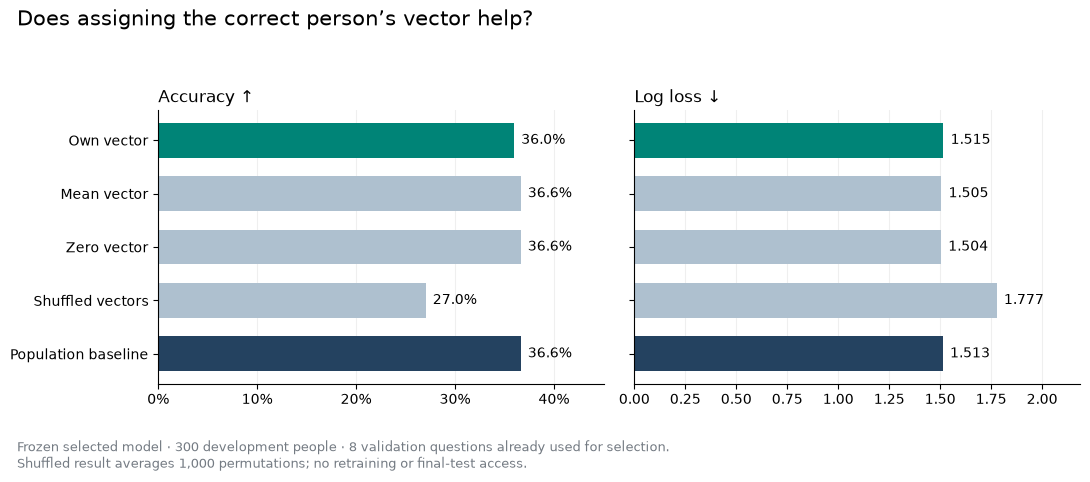

8776

In [3]:
names = ["Own vector", "Mean vector", "Zero vector", "Shuffled vectors", "Population baseline"]
colors = ["#008477", "#AEC0CF", "#AEC0CF", "#AEC0CF", "#244260"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, metric, title in zip(axes, ["accuracy", "nll"], ["Accuracy ↑", "Log loss ↓"]):
    values = [results[n][metric] if n != "Shuffled vectors" else shuffle_summary[metric]["mean"] for n in names]
    ax.barh(names, values, color=colors, height=.65)
    ax.set_title(title, loc="left"); ax.set_axisbelow(True); ax.grid(axis="x", alpha=.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, max(values) * 1.23)
    if metric == "accuracy": ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    for row, value in enumerate(values):
        ax.text(value + max(values)*.02, row, f"{value:.1%}" if metric == "accuracy" else f"{value:.3f}", va="center")
axes[0].invert_yaxis()
fig.suptitle("Does assigning the correct person’s vector help?", fontsize=15, x=.02, ha="left")
fig.text(.02, .025, "Frozen selected model · 300 development people · 8 validation questions already used for selection.\nShuffled result averages 1,000 permutations; no retraining or final-test access.", fontsize=9, color="#747B83")
fig.tight_layout(rect=(0, .12, 1, .92))
exports = []
for ext in ["png", "pdf"]:
    path = OUT / "figures" / f"05_respondent_vector_checks.{ext}"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    exports.append(str(path.relative_to(ROOT)))
plt.show()
for p, digest in hashes.items(): assert sha(p) == digest
summary = {"selected_model": report["selected"], "results": results, "shuffle": shuffle_summary,
           "paired_bootstrap": bootstrap, "source_sha256": hashes, "figures": exports,
           "checks": {"checkpoint_reproduces_saved_predictions": True, "population_baseline_reproduced": True,
                      "shuffling_preserves_aggregate_shares": True, "source_files_unchanged": True},
           "final_test_answers_loaded": False, "model_retrained": False,
           "limitations": ["Exploratory: these questions were already used for model selection.",
                           "Bootstrap intervals resample respondents, not questions, and omit selection uncertainty.",
                           "Ablations hold shared weights fixed; they are not independently retrained alternatives."]}
(OUT / "respondent_vector_checks.json").write_text(json.dumps(summary, indent=2) + "\n")

## Interpretation
Correct vectors beat shuffled vectors (36.0% versus 27.0% accuracy), so identity carries predictive signal. However, removing individual variation reaches 36.6% and slightly improves log loss. Personalization has not demonstrated an overall benefit over a common prediction. The small own-versus-baseline differences fall within respondent-bootstrap uncertainty; these checks are exploratory because validation already informed model selection.

Shuffling preserves aggregate answer shares: matching a survey distribution alone cannot establish that individual personas are accurate. A next experiment could reduce the strength of individual adjustments, keeping the final test sealed.